# Diabetes Progression Prediction Using ANN

## Introduction

In this project, I use an Artificial Neural Network (ANN) to predict diabetes progression using patient-related features. The dataset is taken from the Scikit-learn library.

I will preprocess the data, explore it, build an ANN model and evaluate its performance. I will also try a few changes to improve the model.

In [4]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Libraries imported successfully.")

Libraries imported successfully.


## Loading the Dataset

First, I load the diabetes dataset from Scikit-learn and convert it into a DataFrame for easier analysis.

In [6]:
# Load the dataset
diabetes = load_diabetes()

# Create a DataFrame
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

# Add the target column
df["target"] = diabetes.target

# Display the first five rows
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [7]:
# Check the dataset details
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()

Dataset shape: (442, 11)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Missing values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Statistical summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [8]:
# Fill missing values if any are present
if df.isnull().sum().any():
    df = df.fillna(df.median(numeric_only=True))

print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


The dataset contains 442 rows and 11 columns, including 10 features and the target variable. There are no missing values. The features are already scaled in the original dataset.

## Exploratory Data Analysis

I used histograms, a correlation heatmap and a scatter plot to understand the data and the relationship between features and the target.

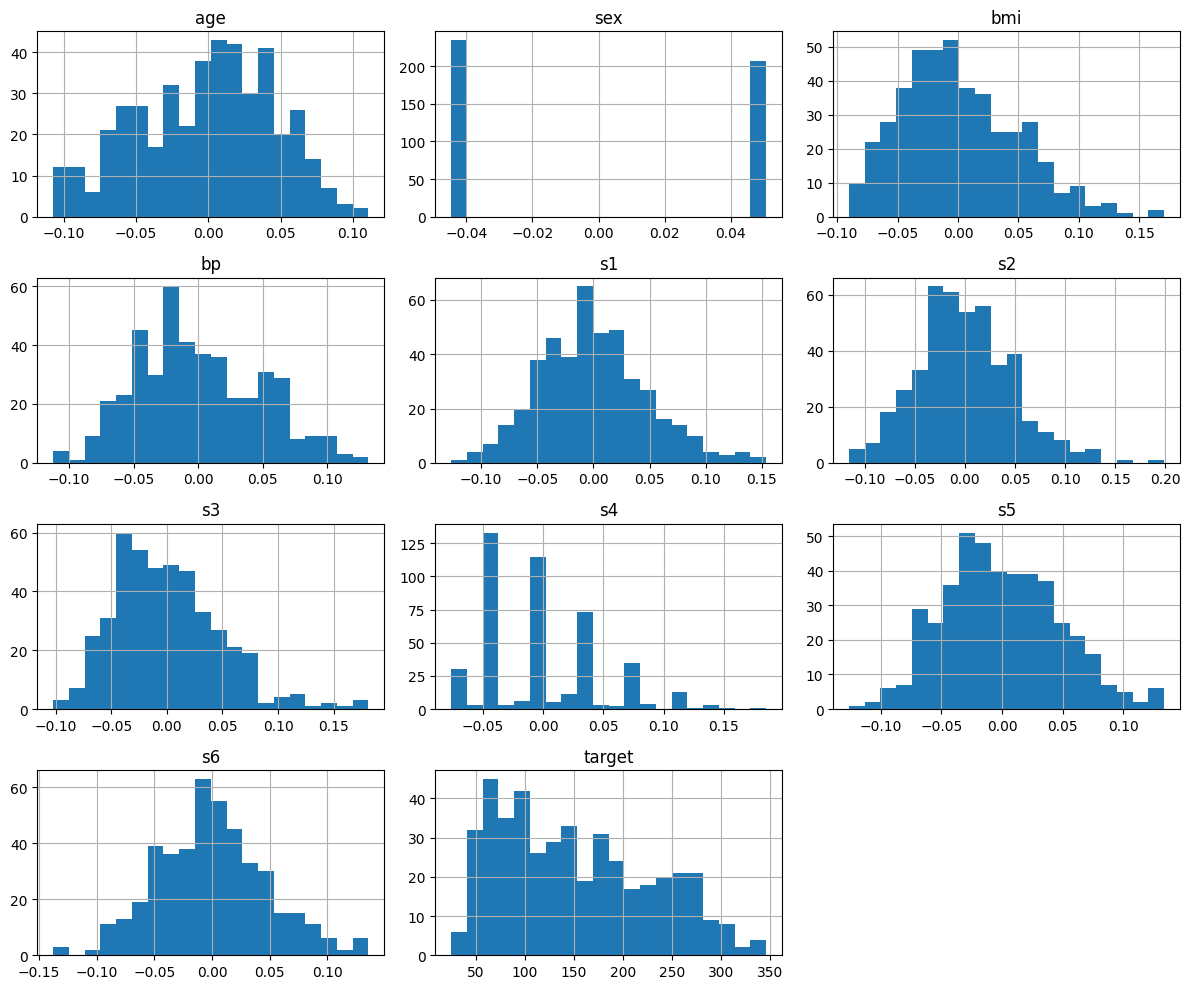

In [9]:
# View the distribution of features and target
df.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

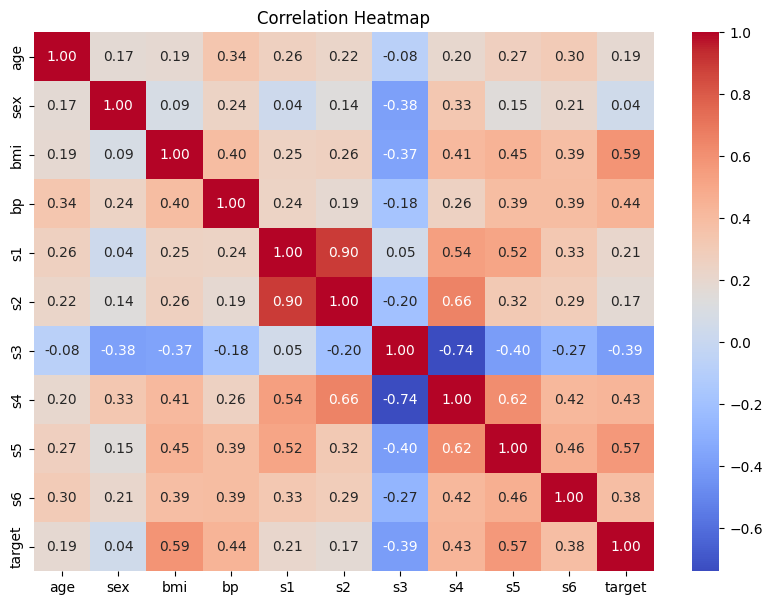

In [10]:
# Check the correlation between variables
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

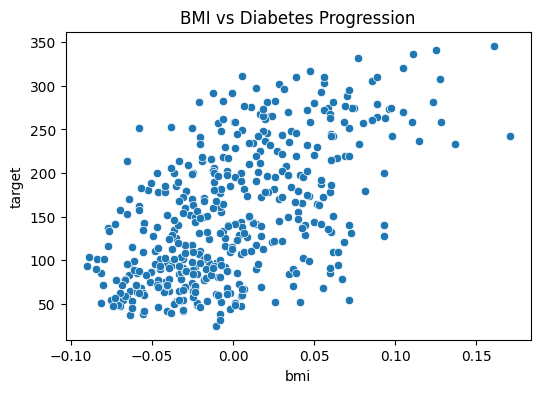

In [11]:
# Relationship between BMI and target
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="bmi", y="target")
plt.title("BMI vs Diabetes Progression")
plt.show()

## Data Preprocessing

I separated the features and target, split the data into training and testing sets, and applied StandardScaler to the features.

In [12]:
# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Normalize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (353, 10)
Testing data shape: (89, 10)


## Building the ANN Model

I created an ANN with two hidden layers using ReLU activation. The output layer has one neuron because this is a regression problem.

In [13]:
# Build the ANN model
model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

## Training the Model

I trained the ANN using the training data. A validation split was used to monitor the model during training.

In [14]:
# Train the model
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 31369.3867 - mae: 158.1777 - val_loss: 22287.3281 - val_mae: 133.3812
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31195.5781 - mae: 157.6621 - val_loss: 22135.3867 - val_mae: 132.8335
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30955.9863 - mae: 156.9450 - val_loss: 21917.5488 - val_mae: 132.0567
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30595.0879 - mae: 155.9012 - val_loss: 21607.0508 - val_mae: 130.9664
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30060.9473 - mae: 154.3808 - val_loss: 21167.3965 - val_mae: 129.4363
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 29317.3887 - mae: 152.2091 - val_loss: 20554.8379 - val_mae: 127.2991
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 28255.9121 - mae: 149.1245 - val_loss: 19733.1914 - val_mae: 124.3763
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 26876.6875 - mae: 144.9664 - val_loss

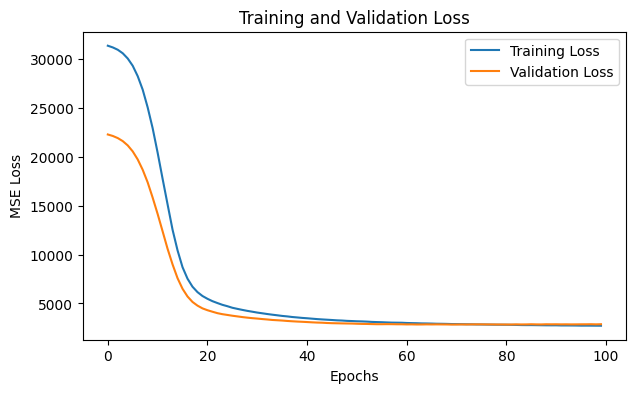

In [15]:
# Plot training and validation loss
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

## Model Evaluation

I evaluated the initial model using the test data. MSE and R² Score were used to measure prediction performance.

In [16]:
# Make predictions
y_pred = model.predict(X_test_scaled).flatten()

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Initial ANN Model")
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 4))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Initial ANN Model
Mean Squared Error: 2815.25
R2 Score: 0.4686


## Model Improvement

I experimented with different ANN architectures, learning rates and target scaling. I compared the results using MSE and R² Score to identify the best-performing model.

In [17]:
# Build a second ANN model
improved_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1)
])

# Compile the model
improved_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="mse",
    metrics=["mae"]
)

# Train the model
improved_history = improved_model.fit(
    X_train_scaled,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

print("Second model training completed.")

Second model training completed.


In [18]:
# Evaluate the second model
improved_pred = improved_model.predict(X_test_scaled).flatten()

improved_mse = mean_squared_error(y_test, improved_pred)
improved_r2 = r2_score(y_test, improved_pred)

print("Second ANN Model")
print("Mean Squared Error:", round(improved_mse, 2))
print("R2 Score:", round(improved_r2, 4))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Second ANN Model
Mean Squared Error: 3907.23
R2 Score: 0.2625


I also try scaling the target values to help the ANN learn more effectively. The predictions are converted back to the original scale before evaluation.

In [22]:
# Scale the target values
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    np.array(y_train).reshape(-1, 1)
)

# Build the third ANN model
model_3 = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

# Compile the model
model_3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Use early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

# Train the model
history_3 = model_3.fit(
    X_train_scaled,
    y_train_scaled,
    epochs=300,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0
)

print("Third model training completed.")
print("Epochs used:", len(history_3.history["loss"]))

Third model training completed.
Epochs used: 88


In [23]:
# Predict using the third model
pred_scaled = model_3.predict(X_test_scaled)

# Convert predictions back to the original scale
pred_3 = y_scaler.inverse_transform(pred_scaled).flatten()

# Calculate evaluation metrics
mse_3 = mean_squared_error(y_test, pred_3)
r2_3 = r2_score(y_test, pred_3)

print("Third ANN Model")
print("Mean Squared Error:", round(mse_3, 2))
print("R2 Score:", round(r2_3, 4))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Third ANN Model
Mean Squared Error: 2876.38
R2 Score: 0.4571


The following table compares the performance of the three ANN models. A lower MSE and a higher R² Score indicate better performance.

In [24]:
# Compare model performance
comparison = pd.DataFrame({
    "Model": ["Initial ANN", "Second ANN", "Third ANN"],
    "MSE": [mse, improved_mse, mse_3],
    "R2 Score": [r2, improved_r2, r2_3]
})

comparison

,Model,MSE,R2 Score
0,Initial ANN,2815.247982,0.468636
1,Second ANN,3907.229377,0.262530
2,Third ANN,2876.378335,0.457098


## Conclusion

In this project, I used an Artificial Neural Network to predict diabetes progression using the Scikit-learn diabetes dataset.

I performed data preprocessing, EDA, model training and evaluation using MSE and R² Score.

I experimented with three ANN models. The initial ANN performed best, with an MSE of 2815.25 and an R² Score of 0.4686. The other experiments did not improve the results.

This project helped me understand how ANN models work for regression problems and how different model settings affect performance.